# HW1 Part D - SEIR Model with Births and Deaths

SEIR equations:

- dS/dt = mu*N - beta*S*I - mu*S
- dE/dt = beta*S*I - (sigma + mu)*E
- dI/dt = sigma*E - (gamma + mu)*I
- dR/dt = gamma*I - mu*R

E = exposed (infected but not infectious yet). 
I am using forward Euler again for solving this.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## i. SEIR function

In [2]:
def seir_model(S0, E0, I0, R0, N, beta, gamma, sigma, mu, days, dt=0.1):
    n = int(days / dt)

    t = np.zeros(n + 1)
    S = np.zeros(n + 1)
    E = np.zeros(n + 1)
    I = np.zeros(n + 1)
    R = np.zeros(n + 1)

    S[0] = S0
    E[0] = E0
    I[0] = I0
    R[0] = R0

    for k in range(n):
        dS = mu * N - beta * S[k] * I[k] - mu * S[k]
        dE = beta * S[k] * I[k] - (sigma + mu) * E[k]
        dI = sigma * E[k] - (gamma + mu) * I[k]
        dR = gamma * I[k] - mu * R[k]

        S[k + 1] = S[k] + dt * dS
        E[k + 1] = E[k] + dt * dE
        I[k + 1] = I[k] + dt * dI
        R[k + 1] = R[k] + dt * dR
        t[k + 1] = t[k] + dt

    return t, S, E, I, R

## ii. Simulation for 365 days and 1500 days

In [3]:
N = 2000
beta = 0.125e-3
gamma = 0.1
sigma = 0.25
mu = 0.005

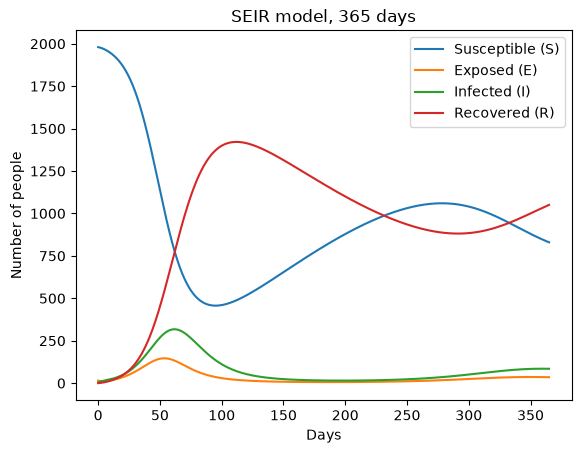

In [4]:
# 365 days
t, S, E, I, R = seir_model(1980, 15, 5, 0, N, beta, gamma, sigma, mu, 365)

plt.plot(t, S, label='Susceptible (S)')
plt.plot(t, E, label='Exposed (E)')
plt.plot(t, I, label='Infected (I)')
plt.plot(t, R, label='Recovered (R)')
plt.xlabel('Days')
plt.ylabel('Number of people')
plt.title('SEIR model, 365 days')
plt.legend()
plt.show()

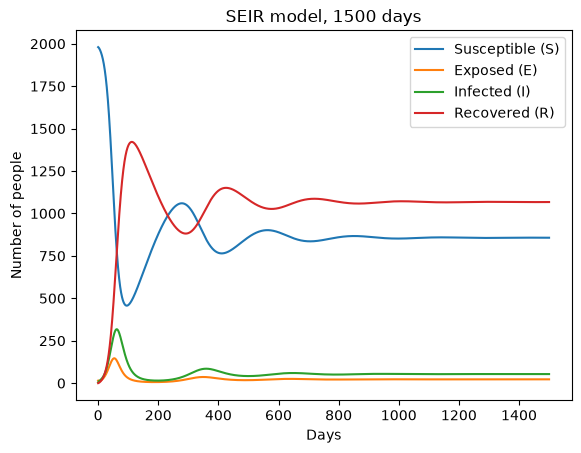

In [6]:
# 1500 days
t, S, E, I, R = seir_model(1980, 15, 5, 0, N, beta, gamma, sigma, mu, 1500)

plt.plot(t, S, label='Susceptible (S)')
plt.plot(t, E, label='Exposed (E)')
plt.plot(t, I, label='Infected (I)')
plt.plot(t, R, label='Recovered (R)')
plt.xlabel('Days')
plt.ylabel('Number of people')
plt.title('SEIR model, 1500 days')
plt.legend()
plt.show()

## iii. Epidemic waves

Finding the peaks (waves) of I by checking where I is bigger than the points before and after it.

Wave peaks:
day 61.7   infected = 317.6
day 359.4   infected = 85.1
day 648.0   infected = 59.7
day 937.8   infected = 54.8
day 1227.9   infected = 53.7

Low points between waves:
day 197.5   infected = 15.0
day 500.1   infected = 41.7
day 792.0   infected = 50.5
day 1082.7   infected = 52.7
day 1373.0   infected = 53.2


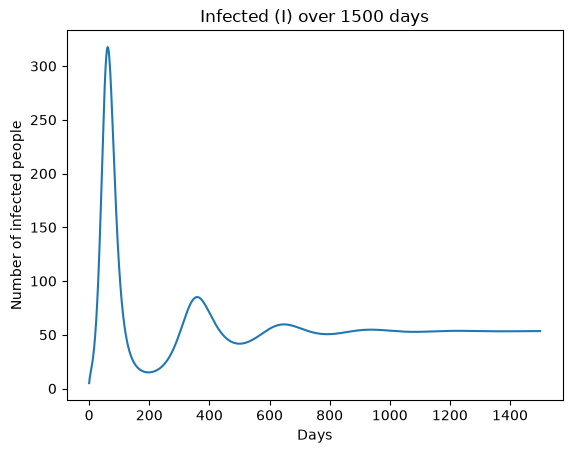

In [7]:
print('Wave peaks:')
for k in range(1, len(I) - 1):
    if I[k] > I[k - 1] and I[k] >= I[k + 1]:
        print('day', round(t[k], 1), '  infected =', round(I[k], 1))

print()
print('Low points between waves:')
for k in range(1, len(I) - 1):
    if I[k] < I[k - 1] and I[k] <= I[k + 1]:
        print('day', round(t[k], 1), '  infected =', round(I[k], 1))

plt.plot(t, I)
plt.xlabel('Days')
plt.ylabel('Number of infected people')
plt.title('Infected (I) over 1500 days')
plt.show()

**Discussion:**

There are several waves, and each one is smaller than the one before:
- The first wave is the big one, like in the SIR model. After it, I drops to about 15 around day 197.
- The waves come about every 290 days.
- After the first wave the next ones are very small bumps, and I settles to a steady level of about 53 infected.

Why waves happen: after the first wave there are not many susceptible people left, so the infection goes down. But births keep adding new susceptible people. When there are enough of them again, the infection grows again and makes a new wave.

In my hypothesis, I expected multiple waves due to birth adding new healthy people and overtime dying down to steady levels. This matches my hypothesis.

## iv. Basic reproduction number

In [8]:
R0_seir = beta * N * sigma / ((sigma + mu) * (gamma + mu))
R0_sir = beta * N / gamma

print('R0 SEIR =', round(R0_seir, 3))
print('R0 SIR (Part C) =', R0_sir)
print()
print('N / R0 =', round(N / R0_seir, 1))
print('S at the end of 1500 days =', round(S[-1], 1))

R0 SEIR = 2.334
R0 SIR (Part C) = 2.5

N / R0 = 856.8
S at the end of 1500 days = 856.9


**Discussion:**

R0 is the average number of people that one infected person infects when everyone else is susceptible.

R0 (SEIR) = 2.33, which is a bit lower than R0 = 2.5 from Part C. It is lower because of the extra terms:
- sigma / (sigma + mu): some exposed people die before they become infectious.
- 1 / (gamma + mu): people stop being infectious(recover or death), so they are infectious for a little less time.

N / R0 = about 857. In the simulation, S at the end is also about 857, so they match.

What this number means: it is the number of susceptible people where each infected person infects exactly one other person on average (the effective reproduction number is 1). 

Disclosure about the part below : Searched on google about herd immunity and how it is achieved.
About 1 - 1/R0 = 57% of people need to be immune to stop the spread (herd immunity).


## v. Effect of the exposed compartment and births/deaths

**Exposed compartment (E):**
- People have to wait about 1/sigma = 4 days before they can infect others.
- Compared with the SIR model in Part B, the first peak comes later (around day 62 instead of day 42) and is lower (about 318 instead of about 470). Some of the infected people are "hidden" in E, so fewer are in I.

**Births and deaths (mu):**
- SIR model outbreak ends because S only goes down. SEIR model births keep adding new susceptible people, so the disease can come back again and again. This is what causes the multiple waves.
- Deaths also remove recovered (immune) people.

**Realistic lifespan:**
- mu = 0.005 means an average lifespan of 1/mu = 200 days, which is very short. A real human lifespan is about 70-80 years, so mu would be around 1/(75*365) = 0.00004 per day.
- New susceptible people would be added very slowly. So for another waveit would takeyears instead of about 290 days.
- SEIR would look almost the same as the SIR model as both would have one wave in such short timespan compared realistic human life.